# Road Accident Analysis – Sample Data Analyst Project
**Audience:** Data Analyst track learners | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
The traffic-safety department wants to understand **which primary cause of accidents is the most dangerous**, so it can focus enforcement and awareness campaigns on it.

**Questions we will answer** (analysis by one factor: **Primary Cause**)
1. How fast were drivers going compared with the speed limit?
2. How serious are the accidents overall?
3. Which cause has the highest fatal-accident rate?
4. How does each cause spread across the severity levels?

> The dataset is **synthetic** (practice data) and is not official road-safety data.

## 2. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

# Find the data file: same folder as the notebook, or the project's data/raw folder
FILE = 'Road_Accident_Analysis_200_Records.xlsx'
here = Path.cwd()
RAW = next((p for p in [here/FILE, here/'data'/'raw'/FILE, here.parent/'data'/'raw'/FILE] if p.exists()), None)
if RAW is None:
    raise FileNotFoundError(f'Put {FILE} in the same folder as this notebook: {here}')
ROOT = here if RAW.parent == here else RAW.parent.parent.parent
IMG = ROOT/'images';               IMG.mkdir(exist_ok=True)
CLEAN_DIR = ROOT/'data'/'processed'; CLEAN_DIR.mkdir(parents=True, exist_ok=True)
print('Data file:', RAW.name, '| Saving to:', ROOT)

Data file: Road_Accident_Analysis_200_Records.xlsx | Saving to: /home/claude/rap/Road_Accident_Analysis_Project


## 3. Load and inspect the data

In [2]:
df = pd.read_excel(RAW)
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (201, 20)


,Accident_ID,Date,Day_of_Week,Time,City,Road_Type,Weather_Condition,Light_Condition,Road_Surface,Primary_Vehicle_Type,Vehicles_Involved,Primary_Cause,Speed_Limit_kmh,Estimated_Speed_kmh,Driver_Age,Driver_Gender,Safety_Gear_Used,Accident_Severity,Injuries,Fatalities
0,ACC-2025001,2025-01-01,Wednesday,10:35:00,Ghaziabad,Residential Street,Rainy,Daylight,Wet / Slippery,Two-Wheeler,1,Overspeeding,30.0,64.0,35.0,Male,No,Property Damage Only,0,0
1,ACC-2025002,2025-01-04,Saturday,08:37:00,Mumbai,National Highway,Clear,Daylight,Dry,Car / SUV,1,Overspeeding,80.0,114.0,43.0,Male,Yes,Fatal,0,1
2,ACC-2025003,2025-01-07,Tuesday,18:04:00,Mumbai,City Arterial Road,Rainy,Dusk / Dawn,Wet / Slippery,Two-Wheeler,2,Overspeeding,50.0,73.0,26.0,Male,Yes,Serious Injury,2,0
3,ACC-2025004,2025-01-12,Sunday,13:04:00,Delhi,Expressway,Clear,Daylight,Dry,Two-Wheeler,1,Drunk Driving,100.0,113.0,42.0,Male,No,Minor Injury,1,0
4,ACC-2025005,2025-01-20,Monday,21:55:00,Jaipur,State Highway,Overcast,Night - Street Lights On,Dry,Two-Wheeler,2,Overspeeding,60.0,101.0,18.0,Male,Yes,Fatal,0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Accident_ID           201 non-null    str           
 1   Date                  200 non-null    datetime64[us]
 2   Day_of_Week           200 non-null    str           
 3   Time                  200 non-null    object        
 4   City                  200 non-null    str           
 5   Road_Type             200 non-null    str           
 6   Weather_Condition     200 non-null    str           
 7   Light_Condition       200 non-null    str           
 8   Road_Surface          200 non-null    str           
 9   Primary_Vehicle_Type  200 non-null    str           
 10  Vehicles_Involved     201 non-null    int64         
 11  Primary_Cause         200 non-null    str           
 12  Speed_Limit_kmh       200 non-null    float64       
 13  Estimated_Speed_kmh   200 non-n

In [4]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.tail(2)

Missing values per column:
Date                    1
Day_of_Week             1
Time                    1
City                    1
Road_Type               1
Weather_Condition       1
Light_Condition         1
Road_Surface            1
Primary_Vehicle_Type    1
Primary_Cause           1
Speed_Limit_kmh         1
Estimated_Speed_kmh     1
Driver_Age              1
Driver_Gender           1
Safety_Gear_Used        1
Accident_Severity       1
dtype: int64

Duplicate rows: 0


,Accident_ID,Date,Day_of_Week,Time,City,Road_Type,Weather_Condition,Light_Condition,Road_Surface,Primary_Vehicle_Type,Vehicles_Involved,Primary_Cause,Speed_Limit_kmh,Estimated_Speed_kmh,Driver_Age,Driver_Gender,Safety_Gear_Used,Accident_Severity,Injuries,Fatalities
199,ACC-2025200,2026-10-13,Tuesday,03:29:00,Bengaluru,City Arterial Road,Clear,Night - Street Lights On,Dry,Auto-Rickshaw,2,Distracted Driving / Mobile Use,50.0,57.0,30.0,Female,Yes,Minor Injury,2,0
200,Total,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,408,NaN,NaN,NaN,NaN,NaN,NaN,NaN,374,54


**What we found:** the last row is a typed `Total` row (not a real accident), so most columns are empty there and `Vehicles_Involved` shows a huge value (408). We remove it next. There are no duplicate accident records.

## 4. Clean the data

In [5]:
clean = df.copy()
# 1. Remove the Total row (it is a summary, not an accident)
clean = clean[clean['Accident_ID'].str.strip().str.lower() != 'total']
# 2. Remove duplicate rows
clean = clean.drop_duplicates()
# 3. Standardise text (remove extra spaces)
for c in clean.select_dtypes(include=['object','string']).columns:
    clean[c] = clean[c].astype(str).str.strip() if c != 'Time' else clean[c]
# 4. Correct data types
clean['Date'] = pd.to_datetime(clean['Date'])
clean['Time'] = clean['Time'].astype(str)
for c in ['Speed_Limit_kmh','Estimated_Speed_kmh','Driver_Age']:
    clean[c] = clean[c].astype(int)
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 200 | Missing values left: 0


## 5. Create new columns (feature engineering)

In [6]:
clean['Speed_Excess_kmh'] = clean['Estimated_Speed_kmh'] - clean['Speed_Limit_kmh']   # km/h above the limit
clean['Is_Fatal'] = (clean['Accident_Severity'] == 'Fatal').astype(int)               # 1 = fatal accident
severity_order = ['Property Damage Only', 'Minor Injury', 'Serious Injury', 'Fatal']
clean[['Accident_ID','Primary_Cause','Speed_Excess_kmh','Accident_Severity','Is_Fatal']].head()

,Accident_ID,Primary_Cause,Speed_Excess_kmh,Accident_Severity,Is_Fatal
0,ACC-2025001,Overspeeding,34,Property Damage Only,0
1,ACC-2025002,Overspeeding,34,Fatal,1
2,ACC-2025003,Overspeeding,23,Serious Injury,0
3,ACC-2025004,Drunk Driving,13,Minor Injury,0
4,ACC-2025005,Overspeeding,41,Fatal,1


## 6. Exploratory data analysis (EDA)

### Q1. How fast were drivers going compared with the limit? (Histogram)

count    200.0
mean      14.8
std       21.5
min      -15.0
25%       -2.2
50%        8.0
75%       34.0
max       55.0
Name: Speed_Excess_kmh, dtype: float64


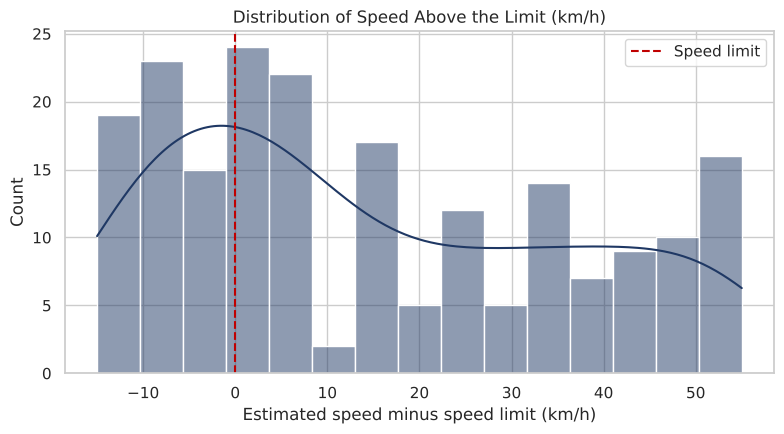

In [7]:
print(clean['Speed_Excess_kmh'].describe().round(1))
plt.figure(figsize=(8,4.5))
sns.histplot(clean['Speed_Excess_kmh'], bins=15, kde=True, color='#1F3864')
plt.axvline(0, color='#C00000', linestyle='--', label='Speed limit')
plt.title('Distribution of Speed Above the Limit (km/h)'); plt.xlabel('Estimated speed minus speed limit (km/h)')
plt.legend(); plt.tight_layout(); plt.savefig(IMG/'01_speed_histogram.png'); plt.show()

### Q2. How serious are the accidents overall? (Pie chart)

Accident_Severity
Property Damage Only    25
Minor Injury            62
Serious Injury          70
Fatal                   43
Name: count, dtype: int64


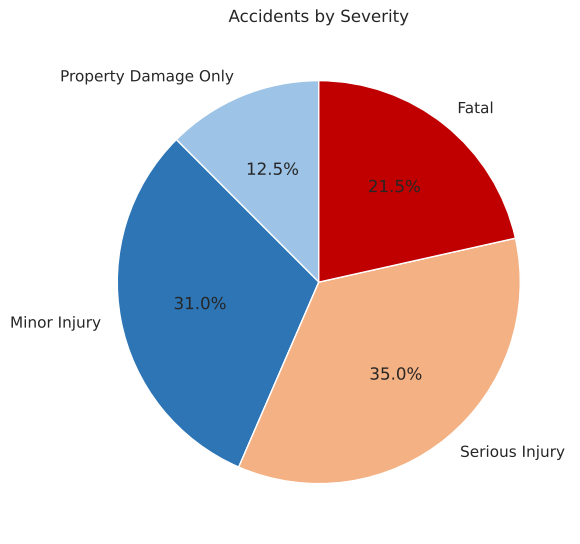

In [8]:
sev = clean['Accident_Severity'].value_counts().reindex(severity_order)
print(sev)
plt.figure(figsize=(6,6))
plt.pie(sev, labels=sev.index, autopct='%1.1f%%', startangle=90,
        colors=['#9DC3E6','#2E75B6','#F4B183','#C00000'], wedgeprops={'edgecolor':'white'})
plt.title('Accidents by Severity'); plt.tight_layout(); plt.savefig(IMG/'02_severity_pie.png'); plt.show()

### Q3. Which cause has the highest fatal-accident rate? (Bar chart)

                                      Accidents  Fatal  Fatal_Rate_%
Primary_Cause                                                       
Overspeeding                                 78     32          41.0
Driver Fatigue                                9      2          22.2
Drunk Driving                                23      5          21.7
Mechanical / Tyre Failure                     7      1          14.3
Jumping Red Light / Signal Violation         19      2          10.5
Distracted Driving / Mobile Use              35      1           2.9
Poor Visibility / Weather                    20      0           0.0
Wrong-Side Driving                            9      0           0.0


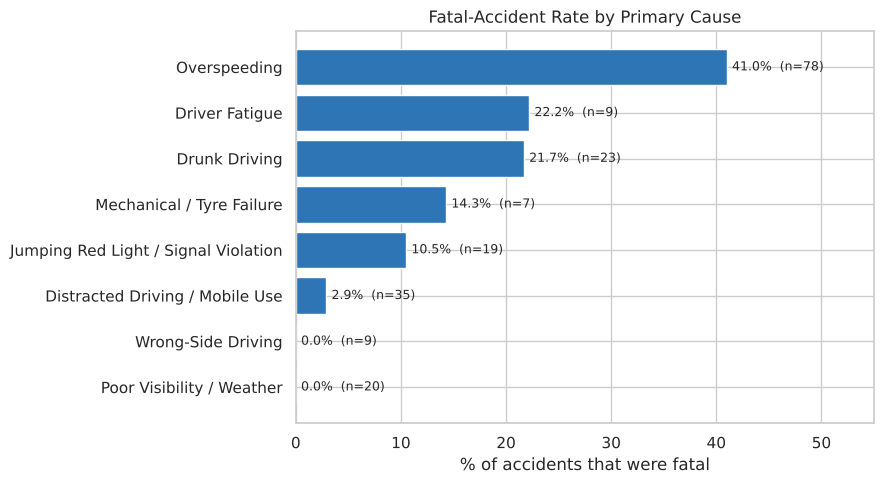

In [9]:
cause = clean.groupby('Primary_Cause').agg(Accidents=('Accident_ID','count'), Fatal=('Is_Fatal','sum'))
cause['Fatal_Rate_%'] = (cause['Fatal']/cause['Accidents']*100).round(1)
cause = cause.sort_values('Fatal_Rate_%')
print(cause.sort_values('Fatal_Rate_%', ascending=False))
plt.figure(figsize=(9,5))
bars = plt.barh(cause.index, cause['Fatal_Rate_%'], color='#2E75B6')
for b, n in zip(bars, cause['Accidents']):
    plt.text(b.get_width()+0.5, b.get_y()+b.get_height()/2, f'{b.get_width():.1f}%  (n={n})', va='center', fontsize=9)
plt.title('Fatal-Accident Rate by Primary Cause'); plt.xlabel('% of accidents that were fatal'); plt.xlim(0, 55)
plt.tight_layout(); plt.savefig(IMG/'03_cause_fatal_rate.png'); plt.show()

### Q4. How does each cause spread across severity levels? (Heatmap)

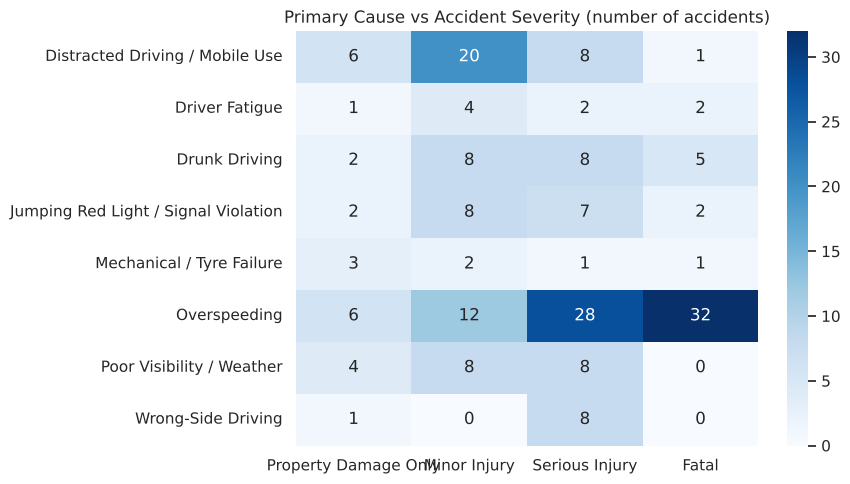

In [10]:
heat = pd.crosstab(clean['Primary_Cause'], clean['Accident_Severity'])[severity_order]
plt.figure(figsize=(9,5))
sns.heatmap(heat, annot=True, fmt='d', cmap='Blues')
plt.title('Primary Cause vs Accident Severity (number of accidents)'); plt.xlabel(''); plt.ylabel('')
plt.tight_layout(); plt.savefig(IMG/'04_cause_severity_heatmap.png'); plt.show()

## 7. Key insights (generated from the data)

In [11]:
top = cause.sort_values('Accidents', ascending=False).index[0]
big = cause[cause['Accidents'] >= 10]
deadliest = big['Fatal_Rate_%'].idxmax()
safest = big['Fatal_Rate_%'].idxmin()
over = (clean['Speed_Excess_kmh'] > 0).mean()*100
print(f"1. Total accidents analysed: {len(clean)}; fatal accidents: {clean['Is_Fatal'].sum()} ({clean['Is_Fatal'].mean()*100:.1f}%).")
print(f"2. Most common cause: {top} ({cause.loc[top,'Accidents']} accidents, {cause.loc[top,'Accidents']/len(clean)*100:.0f}% of all).")
print(f"3. Highest fatal rate (causes with 10+ accidents): {deadliest} at {big.loc[deadliest,'Fatal_Rate_%']}%.")
print(f"4. Lowest fatal rate (causes with 10+ accidents): {safest} at {big.loc[safest,'Fatal_Rate_%']}%.")
print(f"5. {over:.0f}% of drivers were above the speed limit; the typical driver was {clean['Speed_Excess_kmh'].median():.0f} km/h over.")

1. Total accidents analysed: 200; fatal accidents: 43 (21.5%).
2. Most common cause: Overspeeding (78 accidents, 39% of all).
3. Highest fatal rate (causes with 10+ accidents): Overspeeding at 41.0%.
4. Lowest fatal rate (causes with 10+ accidents): Poor Visibility / Weather at 0.0%.
5. 66% of drivers were above the speed limit; the typical driver was 8 km/h over.


## 8. Recommendations
- Focus **speed enforcement** (cameras, patrols) because overspeeding is both the most common and the deadliest cause.
- Run **awareness campaigns** against drunk driving, which has the next-highest fatal rate among causes with enough records.
- Keep monitoring distracted driving: it is common, so it should not be ignored even if fewer cases are fatal.

> **Remember:** causes with fewer than 10 accidents (e.g. wrong-side driving, mechanical failure) have too few records for a reliable rate. This analysis shows association, not proof of cause, and the data is synthetic.

## 9. Save the cleaned data

In [12]:
clean.to_csv(CLEAN_DIR/'road_accident_clean.csv', index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 200 rows
